# XAI Modeling & Stakeholder Explanation Evaluation

This companion notebook loads the clean, anomaly-filtered splits produced by `data_exploration.ipynb` under `processed/` and runs **both sequential decision stages** from `description.md`:

1. **Stage 1 (`Accepted` vs. `Rejected` — Application Gate):**
   - Uses **only the 5 clean shared pre-decision features** common to both datasets (`loan_amnt`, `dti`, `risk_score`, `emp_length_years`, `state`). Accepted-only features (`grade`, `int_rate`, `term`) cannot be used here because rejected applications never received a loan or LendingClub grade.
   - Trained on a **50/50 balanced** `2007–2014` sample (`30k Train / 10k Val / 10k Test`) with an explicit **prior-odds logit calibration** check back to the ~7.6% real-world acceptance rate.
2. **Stage 2 (`Fully Paid` vs. `Default` — Conditional on Acceptance):**
   - Uses the **matured 2013–2015 cohort** (`34,397 Train / 11,466 Val / 11,466 Test`, `14.57%` default rate) across **33 curated non-leaky origination features** (`grade_num`, `sub_grade_num`, `emp_length_years`, `emp_length_missing`, `int_rate`, `term_months`, `dti`, `annual_inc`, `fico_range_low`, `credit_history_years`, `purpose`, `home_ownership`, `verification_status`, `addr_state`, and vetted bureau fields).

### Model Progression, Saved Weights & XAI Design
- **Models:** `LogisticRegression` (white-box baseline) → `MLPClassifier` (neural baseline) → `RandomForestClassifier` (intermediate) → `ExplainableBoostingClassifier` (`interpret`, glass-box GAM) → `XGBClassifier` (early-stopped on **Validation**) → **`TabPFNClassifier`** mini-experiment in standalone `tabpfn_experiment.ipynb` (saving `artifacts/stage{1,2}_tabpfn_preds.npz`).
- **Model Weights & Caching:** All fitted pipelines, XGBoost models, and MLP weight tensors (`coefs_`, `intercepts_`) are saved under `artifacts/models/`. SHAP bundles are cached in **NumPy (`.npz`)** and **PyTorch (`.pt`)** formats under `artifacts/`.
- **Focused XAI & Evaluation:** Global + Local **SHAP** (`TreeExplainer`), **EBM** shape/interaction terms, small-subset **Shapley Interactions (`shapiq`)**, and quantitative evaluation (Faithfulness via additivity & deletion curves, Perturbation Stability, and 80%-Mass Sparsity) mapped to stakeholder transparency desiderata.

In [10]:
import os
import warnings
from pathlib import Path

os.environ.setdefault("SKRUB_DATA_DIRECTORY", "/tmp/skrub_data")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
)
from interpret.glassbox import ExplainableBoostingClassifier
import xgboost as xgb
import shap
import shapiq

sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
PROCESSED_DIR = Path("processed")
ARTIFACTS_DIR = Path("artifacts")
MODELS_DIR = ARTIFACTS_DIR / "models"
ARTIFACTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FORCE_RECOMPUTE_XAI = False

def make_preprocessor(num_cols, cat_cols, scale_num=True, encode_mode="onehot"):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_num:
        num_steps.append(("scaler", StandardScaler()))
    num_pipe = Pipeline(num_steps)

    if encode_mode == "onehot":
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("enc", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)),
        ])
    elif encode_mode == "ordinal":
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
    else:
        raise ValueError(encode_mode)

    return ColumnTransformer(
        [("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)],
        remainder="drop",
        verbose_feature_names_out=False,
    )

def best_f1_threshold(y_true, y_prob):
    """Tune probability threshold strictly on Validation split."""
    thresholds = np.linspace(0.10, 0.80, 71)
    scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
    return float(thresholds[int(np.argmax(scores))])

def calibrate_balanced_probs(p_bal: np.ndarray, true_prior: float = 0.076) -> np.ndarray:
    """Shift 50/50 balanced model probabilities to match the real-world acceptance base rate."""
    p_clip = np.clip(p_bal, 1e-6, 1 - 1e-6)
    logit_bal = np.log(p_clip / (1 - p_clip))
    logit_cal = logit_bal + np.log(true_prior / (1 - true_prior))
    return 1.0 / (1.0 + np.exp(-logit_cal))

def evaluate_3way(name, model, X_tr, y_tr, X_va, y_va, X_te, y_te, tune_thresh=False):
    p_tr = model.predict_proba(X_tr)[:, 1]
    p_va = model.predict_proba(X_va)[:, 1]
    p_te = model.predict_proba(X_te)[:, 1]
    thresh = best_f1_threshold(y_va, p_va) if tune_thresh else 0.50
    y_te_hat = (p_te >= thresh).astype(int)
    return {
        "model": name,
        "train_roc_auc": round(roc_auc_score(y_tr, p_tr), 4),
        "val_roc_auc": round(roc_auc_score(y_va, p_va), 4),
        "test_roc_auc": round(roc_auc_score(y_te, p_te), 4),
        "auc_gap": round(roc_auc_score(y_tr, p_tr) - roc_auc_score(y_te, p_te), 4),
        "test_pr_auc": round(average_precision_score(y_te, p_te), 4),
        "thresh_used": round(thresh, 2),
        "test_bal_acc": round(balanced_accuracy_score(y_te, y_te_hat), 4),
        "test_f1": round(f1_score(y_te, y_te_hat, zero_division=0), 4),
    }

def save_stage_models(stage_prefix: str, models_dict: dict, mlp_pipe: Pipeline, xgb_model: xgb.XGBClassifier) -> pd.DataFrame:
    """Save fitted sklearn/EBM pipelines (.joblib), XGBoost (.json), and MLP weights (.pt + .npz)."""
    saved_rows = []
    for name, obj in models_dict.items():
        out_path = MODELS_DIR / f"{stage_prefix}_{name}.joblib"
        joblib.dump(obj, out_path, compress=3)
        saved_rows.append({"artifact": out_path.name, "size_kb": round(out_path.stat().st_size / 1024, 1)})

    xgb_path = MODELS_DIR / f"{stage_prefix}_xgb.json"
    xgb_model.save_model(xgb_path)
    saved_rows.append({"artifact": xgb_path.name, "size_kb": round(xgb_path.stat().st_size / 1024, 1)})

    # Export explicit MLP weight tensors & input feature names in PyTorch (.pt) and NumPy (.npz)
    mlp = mlp_pipe.named_steps["clf"]
    in_names = list(mlp_pipe.named_steps["prep"].get_feature_names_out())
    pt_state = {
        f"layer_{i}_weight": torch.tensor(w, dtype=torch.float32) for i, w in enumerate(mlp.coefs_)
    }
    pt_state.update({
        f"layer_{i}_bias": torch.tensor(b, dtype=torch.float32) for i, b in enumerate(mlp.intercepts_)
    })
    pt_bundle = {
        "state_dict": pt_state,
        "hidden_layer_sizes": mlp.hidden_layer_sizes,
        "activation": mlp.activation,
        "n_iter": int(mlp.n_iter_),
        "loss_curve": [float(v) for v in mlp.loss_curve_],
        "feature_names": in_names,
    }
    mlp_pt = MODELS_DIR / f"{stage_prefix}_mlp_weights.pt"
    torch.save(pt_bundle, mlp_pt)
    saved_rows.append({"artifact": mlp_pt.name, "size_kb": round(mlp_pt.stat().st_size / 1024, 1)})

    n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
    layer_shapes = [w.shape for w in mlp.coefs_]
    print(f"[{stage_prefix}] MLP architecture: layers={layer_shapes}, total_params={n_params:,}, epochs={mlp.n_iter_}")
    return pd.DataFrame(saved_rows)

def save_explanation_bundle(stem: str, shap_values, base_value, X_eval, y_true, y_prob, feature_names):
    """Persist SHAP explanations in both NumPy (.npz) and PyTorch (.pt) formats."""
    npz_path = ARTIFACTS_DIR / f"{stem}.npz"
    pt_path = ARTIFACTS_DIR / f"{stem}.pt"
    sv = np.asarray(shap_values, dtype=np.float32)
    Xv = np.asarray(X_eval, dtype=np.float32)
    yv = np.asarray(y_true, dtype=np.int64)
    pv = np.asarray(y_prob, dtype=np.float32)
    bv = float(np.asarray(base_value).ravel()[0])
    fn = np.asarray(list(feature_names))

    np.savez_compressed(
        npz_path, shap_values=sv, base_value=bv, X_eval=Xv, y_true=yv, y_prob=pv, feature_names=fn
    )
    torch.save({
        "shap_values": torch.from_numpy(sv),
        "base_value": torch.tensor(bv, dtype=torch.float32),
        "X_eval": torch.from_numpy(Xv),
        "y_true": torch.from_numpy(yv),
        "y_prob": torch.from_numpy(pv),
        "feature_names": list(feature_names),
    }, pt_path)
    return npz_path, pt_path

def load_or_compute_xgb_shap(stem: str, xgb_model, X_eval_arr, y_true, y_prob, feature_names):
    npz_path = ARTIFACTS_DIR / f"{stem}.npz"
    pt_path = ARTIFACTS_DIR / f"{stem}.pt"
    if not FORCE_RECOMPUTE_XAI and npz_path.exists():
        data = np.load(npz_path, allow_pickle=False)
        print(f"Loaded cached explanations from {npz_path} & {pt_path}")
        return data["shap_values"], float(data["base_value"]), data["X_eval"]

    explainer = shap.TreeExplainer(xgb_model)
    sv = explainer.shap_values(X_eval_arr)
    if isinstance(sv, list):
        sv = sv[1]
    ev = explainer.expected_value
    if isinstance(ev, (list, np.ndarray)):
        ev = float(np.asarray(ev).ravel()[-1])
    save_explanation_bundle(stem, sv, ev, X_eval_arr, y_true, y_prob, feature_names)
    print(f"Computed & cached explanations -> {npz_path} and {pt_path}")
    return np.asarray(sv, dtype=np.float32), float(ev), np.asarray(X_eval_arr, dtype=np.float32)

def evaluate_explanations(xgb_model, X_eval_arr, X_ref_arr, shap_vals, base_val, n_faith=300, n_stab=100):
    """Quantitative evaluation aligned with stakeholder desiderata: Faithfulness, Stability, Sparsity."""
    rng = np.random.default_rng(RANDOM_STATE)
    # 1. Additivity check (exactness in log-odds space)
    margins = xgb_model.predict(X_eval_arr, output_margin=True)
    max_add_err = float(np.max(np.abs(shap_vals.sum(axis=1) + base_val - margins)))

    # 2. Directional Deletion Faithfulness on predicted-positive cases (p >= 0.5) & overall |SHAP|
    p_all = xgb_model.predict_proba(X_eval_arr)[:, 1]
    pos_pool = np.where(p_all >= 0.5)[0]
    if len(pos_pool) < 50:
        pos_pool = np.argsort(-p_all)[:min(n_faith, len(p_all))]
    sub_idx = rng.choice(pos_pool, size=min(n_faith, len(pos_pool)), replace=False)

    X_sub = X_eval_arr[sub_idx].copy()
    sv_sub = shap_vals[sub_idx]
    medians = np.nanmedian(X_ref_arr, axis=0)
    p_orig = xgb_model.predict_proba(X_sub)[:, 1]

    k_list = [1, 2, 3, min(5, X_sub.shape[1])]
    del_drops_shap, del_drops_rand = {}, {}
    for k in k_list:
        X_mask_s = X_sub.copy()
        X_mask_r = X_sub.copy()
        for r_i in range(len(X_sub)):
            top_k = np.argsort(-sv_sub[r_i])[:k]
            rand_k = rng.choice(X_sub.shape[1], size=k, replace=False)
            X_mask_s[r_i, top_k] = medians[top_k]
            X_mask_r[r_i, rand_k] = medians[rand_k]
        del_drops_shap[k] = float(np.mean(p_orig - xgb_model.predict_proba(X_mask_s)[:, 1]))
        del_drops_rand[k] = float(np.mean(p_orig - xgb_model.predict_proba(X_mask_r)[:, 1]))

    # 3. Perturbation Stability: Spearman correlation under 0.05*std Gaussian jitter
    stab_idx = rng.choice(len(X_eval_arr), size=min(n_stab, len(X_eval_arr)), replace=False)
    X_st = X_eval_arr[stab_idx].copy()
    stds = np.nanstd(X_ref_arr, axis=0)
    stds = np.where(stds > 0, stds, 0.0)
    X_noisy = X_st + rng.normal(0.0, 0.05 * stds, size=X_st.shape)
    sv_noisy = shap.TreeExplainer(xgb_model).shap_values(X_noisy)
    if isinstance(sv_noisy, list):
        sv_noisy = sv_noisy[1]
    corrs = [spearmanr(shap_vals[stab_idx[i]], sv_noisy[i]).statistic for i in range(len(stab_idx))]
    mean_spearman = float(np.nanmean(corrs))

    # 4. Cognitive Sparsity: features needed to reach >= 80% of total |SHAP| mass
    abs_sv = np.abs(shap_vals)
    sorted_abs = np.sort(abs_sv, axis=1)[:, ::-1]
    cum_share = np.cumsum(sorted_abs, axis=1) / np.maximum(sorted_abs.sum(axis=1, keepdims=True), 1e-9)
    k_80 = np.argmax(cum_share >= 0.80, axis=1) + 1

    metrics = {
        "max_additivity_error": round(max_add_err, 6),
        "deletion_prob_drop_top3_shap": round(del_drops_shap[3], 4),
        "deletion_prob_drop_top3_rand": round(del_drops_rand[3], 4),
        "faithfulness_ratio_k3": round(del_drops_shap[3] / max(abs(del_drops_rand[3]), 1e-6), 2),
        "stability_spearman_noise005": round(mean_spearman, 4),
        "mean_features_for_80pct_mass": round(float(np.mean(k_80)), 2),
        "median_features_for_80pct_mass": int(np.median(k_80)),
    }
    return metrics, del_drops_shap, del_drops_rand

---
## 1. Stage 1 — Application Gate (`Accepted` vs. `Rejected`)

Using the 5 clean shared pre-decision features (`loan_amnt`, `dti`, `risk_score`, `emp_length_years`, `state`) on our 50/50 balanced 2007–2014 splits (`30k Train / 10k Val / 10k Test`).

### Guide to the Evaluation Table Columns

- **`train_roc_auc` / `val_roc_auc` / `test_roc_auc`:** Area under the ROC curve across all probability thresholds (`0.50` = random guessing, `1.00` = perfect ranking). Measures how well the model separates positive from negative cases regardless of threshold.
- **`auc_gap` (`train_roc_auc − test_roc_auc`):** Direct overfitting check. Values near `0.00` indicate clean generalization; large positive values indicate the model is memorizing training noise.
- **`test_pr_auc` (Precision–Recall AUC / Average Precision):** Stricter metric under class imbalance. Crucially, the **random-guessing baseline equals the positive class prevalence**: **`0.500`** in Stage 1 (50/50 balanced), and **`0.146`** in Stage 2 (14.56% default rate).
- **`thresh_used`:** Probability cutoff used for hard class predictions (`0.50` for balanced Stage 1; tuned strictly on **Validation** to maximize F1 for imbalanced Stage 2).
- **`test_bal_acc` (Balanced Accuracy):** Average of True Positive Rate (recall) and True Negative Rate (`0.50` = random baseline even under imbalance).
- **`test_f1`:** Harmonic mean of precision and recall on the positive class (`1 = Accepted` in Stage 1; `1 = Default` in Stage 2) at `thresh_used`.

In [11]:
s1_tr = pd.read_csv(PROCESSED_DIR / "stage1_train.csv")
s1_va = pd.read_csv(PROCESSED_DIR / "stage1_val.csv")
s1_te = pd.read_csv(PROCESSED_DIR / "stage1_test.csv")

s1_num_cols = ["loan_amnt", "dti", "risk_score", "emp_length_years"]
s1_cat_cols = ["state"]
s1_feats = s1_num_cols + s1_cat_cols

X1_tr, y1_tr = s1_tr[s1_feats], s1_tr["accepted"]
X1_va, y1_va = s1_va[s1_feats], s1_va["accepted"]
X1_te, y1_te = s1_te[s1_feats], s1_te["accepted"]

# 1. LogisticRegression (Baseline)
s1_lr = Pipeline([
    ("prep", make_preprocessor(s1_num_cols, s1_cat_cols, scale_num=True, encode_mode="onehot")),
    ("clf", LogisticRegression(C=0.5, max_iter=500, random_state=RANDOM_STATE)),
]).fit(X1_tr, y1_tr)

# 2. MLPClassifier (Neural Baseline, early stopping)
s1_mlp = Pipeline([
    ("prep", make_preprocessor(s1_num_cols, s1_cat_cols, scale_num=True, encode_mode="onehot")),
    ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=60, random_state=RANDOM_STATE)),
]).fit(X1_tr, y1_tr)

# 3. RandomForest (Intermediate)
s1_rf = Pipeline([
    ("prep", make_preprocessor(s1_num_cols, s1_cat_cols, scale_num=False, encode_mode="ordinal")),
    ("clf", RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=30, n_jobs=1, random_state=RANDOM_STATE)),
]).fit(X1_tr, y1_tr)

# 4. Explainable Boosting Machine (Glass-box GAM + Interactions)
s1_ebm = ExplainableBoostingClassifier(
    max_bins=64, interactions=4, outer_bags=4, random_state=RANDOM_STATE, n_jobs=1
).fit(X1_tr, y1_tr)

# 5. XGBoost (Early-stopped strictly on Validation split)
s1_xgb_prep = make_preprocessor(s1_num_cols, s1_cat_cols, scale_num=False, encode_mode="ordinal")
X1_tr_enc = s1_xgb_prep.fit_transform(X1_tr)
X1_va_enc = s1_xgb_prep.transform(X1_va)
X1_te_enc = s1_xgb_prep.transform(X1_te)
s1_enc_names = list(s1_xgb_prep.get_feature_names_out())

s1_xgb = xgb.XGBClassifier(
    n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.9,
    reg_lambda=2.0, eval_metric="logloss", early_stopping_rounds=25, n_jobs=1, random_state=RANDOM_STATE,
)
s1_xgb.fit(X1_tr_enc, y1_tr, eval_set=[(X1_va_enc, y1_va)], verbose=False)

s1_results = pd.DataFrame([
    evaluate_3way("LogReg (Baseline)", s1_lr, X1_tr, y1_tr, X1_va, y1_va, X1_te, y1_te),
    evaluate_3way("MLP (Neural Baseline)", s1_mlp, X1_tr, y1_tr, X1_va, y1_va, X1_te, y1_te),
    evaluate_3way("RandomForest (Reg)", s1_rf, X1_tr, y1_tr, X1_va, y1_va, X1_te, y1_te),
    evaluate_3way("EBM (Glass-box GAM)", s1_ebm, X1_tr, y1_tr, X1_va, y1_va, X1_te, y1_te),
    evaluate_3way("XGBoost (Early-Stopped)", s1_xgb, X1_tr_enc, y1_tr, X1_va_enc, y1_va, X1_te_enc, y1_te),
])
print(f"XGBoost best_iteration: {s1_xgb.best_iteration}")
display(s1_results)

# Save Stage 1 models & MLP weights
s1_saved = save_stage_models(
    "stage1",
    {"logreg": s1_lr, "mlp_pipe": s1_mlp, "rf": s1_rf, "ebm": s1_ebm, "xgb_prep": s1_xgb_prep},
    s1_mlp,
    s1_xgb,
)
display(s1_saved)

XGBoost best_iteration: 499


,model,train_roc_auc,val_roc_auc,test_roc_auc,auc_gap,test_pr_auc,thresh_used,test_bal_acc,test_f1
0,LogReg (Baseline),0.9219,0.9194,0.9263,-0.0044,0.8939,0.5,0.8458,0.8447
1,MLP (Neural Baseline),0.9649,0.9626,0.9629,0.0020,0.9444,0.5,0.9138,0.9156
2,RandomForest (Reg),0.9761,0.9734,0.9746,0.0016,0.9659,0.5,0.9266,0.9270
3,EBM (Glass-box GAM),0.9884,0.9871,0.9888,-0.0004,0.9858,0.5,0.9552,0.9560
4,XGBoost (Early-Stopped),0.9952,0.9935,0.9936,0.0017,0.9913,0.5,0.9681,0.9686


[stage1] MLP architecture: layers=[(34, 64), (64, 32), (32, 1)], total_params=4,353, epochs=24


,artifact,size_kb
0,stage1_logreg.joblib,2.7
1,stage1_mlp_pipe.joblib,105.0
2,stage1_rf.joblib,614.2
3,stage1_ebm.joblib,436.8
4,stage1_xgb_prep.joblib,1.5
5,stage1_xgb.json,792.5
6,stage1_mlp_weights.pt,20.8


Loaded cached explanations from artifacts/stage1_xgb_shap.npz & artifacts/stage1_xgb_shap.pt
Top Stage 1 2-way Shapley interactions (shapiq, n=100):


,mean_abs_shapiq_2way
risk_score x emp_length_years,0.373868
dti x risk_score,0.279918
dti x emp_length_years,0.145221
loan_amnt x risk_score,0.102471
risk_score x state,0.064867
loan_amnt x dti,0.060445


Stage 1 Explanation Evaluation: {'max_additivity_error': 1.3e-05, 'deletion_prob_drop_top3_shap': -0.0154, 'deletion_prob_drop_top3_rand': -0.0327, 'faithfulness_ratio_k3': -0.47, 'stability_spearman_noise005': 0.549, 'mean_features_for_80pct_mass': 2.34, 'median_features_for_80pct_mass': 2}

Stage 1 Accepted Applicant | idx=883 | true=1 | P_bal(accept)=0.996 | P_cal(7.6% prior)=0.951


,feature,value,shap_log_odds
2,risk_score,662.0,2.262524
3,emp_length_years,8.0,1.600077
0,loan_amnt,9450.0,0.738630
1,dti,14.72,0.476000
4,state,WA,0.398649



Stage 1 Rejected Applicant | idx=1535 | true=0 | P_bal(accept)=0.000 | P_cal(7.6% prior)=0.000


,feature,value,shap_log_odds
2,risk_score,586.0,-5.464725
1,dti,47.93,-3.458794
3,emp_length_years,0.0,-1.065142
0,loan_amnt,15000.0,-0.518090
4,state,OK,-0.065769


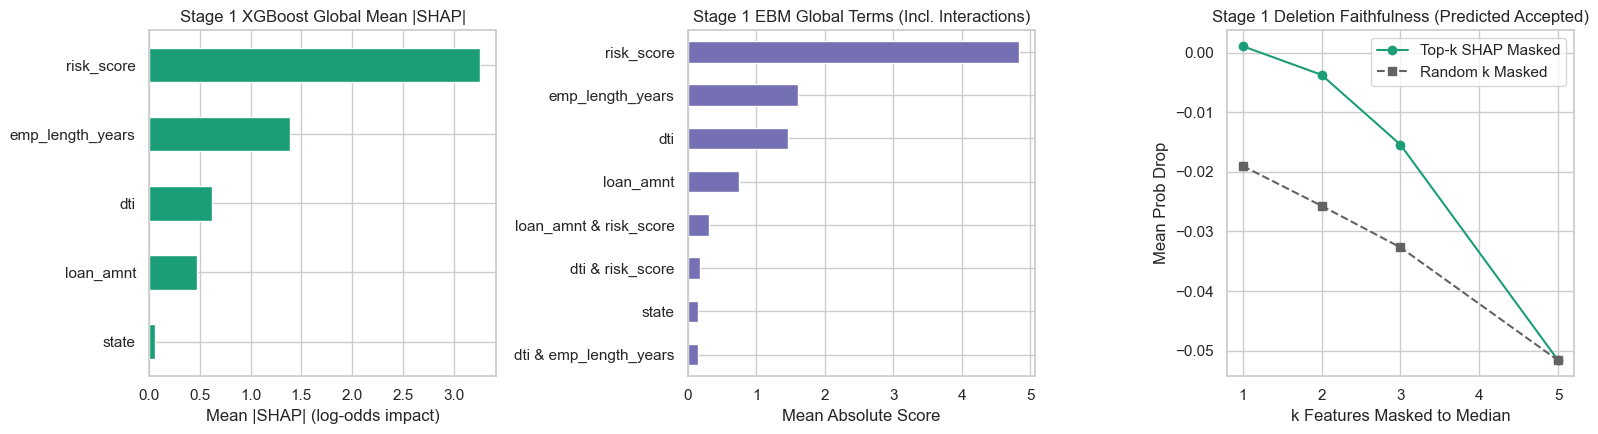

In [13]:
# Stage 1 XAI: SHAP (cached .npz/.pt) + EBM Global Terms + shapiq Interactions + Evaluation
N_EXPLAIN_S1 = 2000
X1_eval_enc = X1_te_enc[:N_EXPLAIN_S1]
y1_eval = y1_te.iloc[:N_EXPLAIN_S1].to_numpy()
p1_eval = s1_xgb.predict_proba(X1_eval_enc)[:, 1]
p1_eval_cal = calibrate_balanced_probs(p1_eval, true_prior=0.076)

s1_shap, s1_base, _ = load_or_compute_xgb_shap(
    "stage1_xgb_shap", s1_xgb, X1_eval_enc, y1_eval, p1_eval, s1_enc_names
)

# shapiq 2-way interactions on a compact subset (n=100)
sq1 = shapiq.TreeExplainer(model=s1_xgb, max_order=2, index="k-SII")
s1_pair_sums = {}
for i in range(100):
    iv = sq1.explain(X1_eval_enc[i])
    for tup, val in iv.dict_values.items():
        if len(tup) == 2:
            name = f"{s1_enc_names[tup[0]]} x {s1_enc_names[tup[1]]}"
            s1_pair_sums[name] = s1_pair_sums.get(name, 0.0) + abs(float(val))
s1_pairs_df = (
    pd.Series({k: v / 100.0 for k, v in s1_pair_sums.items()})
    .sort_values(ascending=False)
    .to_frame("mean_abs_shapiq_2way")
)
print("Top Stage 1 2-way Shapley interactions (shapiq, n=100):")
display(s1_pairs_df.head(6))

# Evaluate Stage 1 explanations (on predicted-accepted cases so masking top positive drivers lowers P(accept))
s1_eval_metrics, s1_del_shap, s1_del_rand = evaluate_explanations(
    s1_xgb, X1_eval_enc, X1_tr_enc, s1_shap, s1_base
)
print("Stage 1 Explanation Evaluation:", s1_eval_metrics)

# Local applicant examples (Accepted vs. Rejected) with prior-odds calibrated probability note
acc_i = int(np.argmax(p1_eval * (y1_eval == 1)))
rej_i = int(np.argmin(p1_eval + (y1_eval == 1)))
for label, idx in [("Stage 1 Accepted Applicant", acc_i), ("Stage 1 Rejected Applicant", rej_i)]:
    loc1 = pd.DataFrame({
        "feature": s1_enc_names,
        "value": X1_te.iloc[idx][s1_enc_names].values,
        "shap_log_odds": s1_shap[idx],
    }).sort_values("shap_log_odds", key=lambda s: s.abs(), ascending=False)
    print(f"\n{label} | idx={idx} | true={y1_eval[idx]} | P_bal(accept)={p1_eval[idx]:.3f} | P_cal(7.6% prior)={p1_eval_cal[idx]:.3f}")
    display(loc1)

# Visual summary: Global SHAP, EBM Global Importances, and Deletion Faithfulness Curve
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

pd.Series(np.abs(s1_shap).mean(axis=0), index=s1_enc_names).sort_values().plot(
    kind="barh", ax=axes[0], color="#1b9e77"
)
axes[0].set_title("Stage 1 XGBoost Global Mean |SHAP|")
axes[0].set_xlabel("Mean |SHAP| (log-odds impact)")

ebm1_glob = s1_ebm.explain_global().data()
pd.Series(ebm1_glob["scores"], index=ebm1_glob["names"]).sort_values().tail(8).plot(
    kind="barh", ax=axes[1], color="#7570b3"
)
axes[1].set_title("Stage 1 EBM Global Terms (Incl. Interactions)")
axes[1].set_xlabel("Mean Absolute Score")

ks = sorted(s1_del_shap.keys())
axes[2].plot(ks, [s1_del_shap[k] for k in ks], marker="o", label="Top-k SHAP Masked", color="#1b9e77")
axes[2].plot(ks, [s1_del_rand[k] for k in ks], marker="s", linestyle="--", label="Random k Masked", color="#636363")
axes[2].set_title("Stage 1 Deletion Faithfulness (Predicted Accepted)")
axes[2].set_xlabel("k Features Masked to Median")
axes[2].set_ylabel("Mean Prob Drop")
axes[2].legend()

plt.tight_layout()
plt.show()

---
## 2. Stage 2 — Default Risk Among Accepted Borrowers (`Fully Paid` vs. `Default`)

Using the clean, matured 2013–2015 cohort (`34,397 Train / 11,466 Val / 11,466 Test`, `14.57%` default rate) across 33 non-redundant origination features (`grade_num`, `sub_grade_num`, `emp_length_years`, `emp_length_missing`, `int_rate`, `term_months`, `dti`, `annual_inc`, `fico_range_low`, `credit_history_years`, `purpose`, `home_ownership`, `verification_status`, `addr_state`, and vetted bureau fields).

In [ ]:
s2_tr = pd.read_csv(PROCESSED_DIR / "stage2_train.csv")
s2_va = pd.read_csv(PROCESSED_DIR / "stage2_val.csv")
s2_te = pd.read_csv(PROCESSED_DIR / "stage2_test.csv")

# Drop raw 'grade' string since 'grade_num' (1..7) and 'sub_grade_num' (1..35) capture ordinal risk cleanly
drop_meta = {"grade", "issue_year", "default"}
s2_feats = [c for c in s2_tr.columns if c not in drop_meta]
s2_cat_cols = [c for c in s2_feats if s2_tr[c].dtype == object or str(s2_tr[c].dtype) == "string"]
s2_num_cols = [c for c in s2_feats if c not in s2_cat_cols]

X2_tr, y2_tr = s2_tr[s2_feats], s2_tr["default"]
X2_va, y2_va = s2_va[s2_feats], s2_va["default"]
X2_te, y2_te = s2_te[s2_feats], s2_te["default"]

# 1. LogisticRegression (White-box baseline)
s2_lr = Pipeline([
    ("prep", make_preprocessor(s2_num_cols, s2_cat_cols, scale_num=True, encode_mode="onehot")),
    ("clf", LogisticRegression(C=0.25, max_iter=600, class_weight="balanced", random_state=RANDOM_STATE)),
]).fit(X2_tr, y2_tr)

# 2. MLPClassifier (Neural baseline)
s2_mlp = Pipeline([
    ("prep", make_preprocessor(s2_num_cols, s2_cat_cols, scale_num=True, encode_mode="onehot")),
    ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-2, early_stopping=True, max_iter=60, random_state=RANDOM_STATE)),
]).fit(X2_tr, y2_tr)

# 3. RandomForest (Intermediate regularized)
s2_rf = Pipeline([
    ("prep", make_preprocessor(s2_num_cols, s2_cat_cols, scale_num=False, encode_mode="ordinal")),
    ("clf", RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=50, class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE)),
]).fit(X2_tr, y2_tr)

# 4. Explainable Boosting Machine (Glass-box GAM + Interactions)
s2_ebm = ExplainableBoostingClassifier(
    max_bins=64, interactions=6, outer_bags=4, random_state=RANDOM_STATE, n_jobs=1
).fit(X2_tr.fillna({"emp_length_years": X2_tr["emp_length_years"].median()}), y2_tr)

# 5. XGBoost (Full Origination, early-stopped on Validation)
s2_xgb_prep = make_preprocessor(s2_num_cols, s2_cat_cols, scale_num=False, encode_mode="ordinal")
X2_tr_enc = s2_xgb_prep.fit_transform(X2_tr)
X2_va_enc = s2_xgb_prep.transform(X2_va)
X2_te_enc = s2_xgb_prep.transform(X2_te)
s2_enc_names = list(s2_xgb_prep.get_feature_names_out())

s2_xgb = xgb.XGBClassifier(
    n_estimators=600, max_depth=4, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=3.0, min_child_weight=20, eval_metric="auc", early_stopping_rounds=30,
    n_jobs=1, random_state=RANDOM_STATE,
)
s2_xgb.fit(X2_tr_enc, y2_tr, eval_set=[(X2_va_enc, y2_va)], verbose=False)

# 6. XGBoost (Fundamentals Only: excludes LC grade_num, sub_grade_num, int_rate, installment)
lc_pricing = {"grade_num", "sub_grade_num", "int_rate", "installment"}
fund_feats = [c for c in s2_feats if c not in lc_pricing]
fund_num = [c for c in s2_num_cols if c not in lc_pricing]
s2_fund_prep = make_preprocessor(fund_num, s2_cat_cols, scale_num=False, encode_mode="ordinal")
X2f_tr_enc = s2_fund_prep.fit_transform(X2_tr[fund_feats])
X2f_va_enc = s2_fund_prep.transform(X2_va[fund_feats])
X2f_te_enc = s2_fund_prep.transform(X2_te[fund_feats])
s2f_enc_names = list(s2_fund_prep.get_feature_names_out())

s2_xgb_fund = xgb.XGBClassifier(
    n_estimators=600, max_depth=4, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=3.0, min_child_weight=20, eval_metric="auc", early_stopping_rounds=30,
    n_jobs=1, random_state=RANDOM_STATE,
)
s2_xgb_fund.fit(X2f_tr_enc, y2_tr, eval_set=[(X2f_va_enc, y2_va)], verbose=False)

X2_tr_ebm = X2_tr.fillna({"emp_length_years": X2_tr["emp_length_years"].median()})
X2_va_ebm = X2_va.fillna({"emp_length_years": X2_tr["emp_length_years"].median()})
X2_te_ebm = X2_te.fillna({"emp_length_years": X2_tr["emp_length_years"].median()})

s2_results = pd.DataFrame([
    evaluate_3way("LogReg (Baseline)", s2_lr, X2_tr, y2_tr, X2_va, y2_va, X2_te, y2_te, tune_thresh=True),
    evaluate_3way("MLP (Neural Baseline)", s2_mlp, X2_tr, y2_tr, X2_va, y2_va, X2_te, y2_te, tune_thresh=True),
    evaluate_3way("RandomForest (Reg)", s2_rf, X2_tr, y2_tr, X2_va, y2_va, X2_te, y2_te, tune_thresh=True),
    evaluate_3way("EBM (Glass-box GAM)", s2_ebm, X2_tr_ebm, y2_tr, X2_va_ebm, y2_va, X2_te_ebm, y2_te, tune_thresh=True),
    evaluate_3way("XGBoost (Full Orig)", s2_xgb, X2_tr_enc, y2_tr, X2_va_enc, y2_va, X2_te_enc, y2_te, tune_thresh=True),
    evaluate_3way("XGBoost (Fundamentals Only)", s2_xgb_fund, X2f_tr_enc, y2_tr, X2f_va_enc, y2_va, X2f_te_enc, y2_te, tune_thresh=True),
])
print(f"XGBoost Full best_iteration: {s2_xgb.best_iteration} | Fundamentals-Only best_iteration: {s2_xgb_fund.best_iteration}")
display(s2_results)

# Save Stage 2 models & MLP weights
s2_saved = save_stage_models(
    "stage2",
    {"logreg": s2_lr, "mlp_pipe": s2_mlp, "rf": s2_rf, "ebm": s2_ebm, "xgb_prep": s2_xgb_prep, "xgb_fund": s2_xgb_fund},
    s2_mlp,
    s2_xgb,
)
display(s2_saved)

XGBoost Full best_iteration: 229 | Fundamentals-Only best_iteration: 240


,model,train_roc_auc,val_roc_auc,test_roc_auc,auc_gap,test_pr_auc,thresh_used,test_bal_acc,test_f1
0,LogReg (Baseline),0.6931,0.6876,0.6824,0.0107,0.2619,0.55,0.6225,0.3325
1,MLP (Neural Baseline),0.6818,0.6711,0.6733,0.0085,0.2507,0.17,0.6207,0.3237
2,RandomForest (Reg),0.7722,0.6859,0.6781,0.0941,0.2561,0.48,0.6237,0.3259
3,EBM (Glass-box GAM),0.7029,0.6923,0.6832,0.0197,0.2642,0.17,0.6260,0.3337
4,XGBoost (Full Orig),0.7364,0.6923,0.6855,0.0509,0.2606,0.15,0.6360,0.3364
5,XGBoost (Fundamentals Only),0.7378,0.6839,0.6768,0.0610,0.2551,0.16,0.6220,0.3268


[stage2] MLP architecture: layers=[(72, 64), (64, 32), (32, 1)], total_params=6,785, epochs=12


,artifact,size_kb
0,stage2_logreg.joblib,4.6
1,stage2_mlp_pipe.joblib,161.0
2,stage2_rf.joblib,1700.4
3,stage2_ebm.joblib,741.7
4,stage2_xgb_prep.joblib,2.5
5,stage2_xgb_fund.joblib,109.3
6,stage2_xgb.json,429.1
7,stage2_mlp_weights.pt,31.3


### Interpreting Stage 2 Results & Why ROC-AUC Plateaus Around `0.67–0.69`

Across **six completely different model families**—including our standalone **TabPFN v3.5** experiment (`tabpfn_experiment.ipynb`, `1,000 → 500` subset: **Stage 1** `0.9869` ROC-AUC / `0.9735` PR-AUC in `31.0s`; **Stage 2** `0.6688` ROC-AUC / `0.2525` PR-AUC in `1.8s`)—Stage 2 performance consistently lands at **Test ROC-AUC `~0.67–0.69`** and **Test PR-AUC `~0.25–0.26`**:

1. **This is an origination-information ceiling, not model underfitting:**
   - Every borrower in Stage 2 **already passed Stage 1 underwriting** (`Stage 1 ROC-AUC = 0.9936`), so obvious high-risk applicants have already been truncated out.
   - LendingClub's own expert risk score (`sub_grade_num`) alone gets **`0.6548`** Test ROC-AUC (`int_rate` alone gets **`0.6468`**), and adding all 33 origination features + engineered financial ratios raises this to **`0.684–0.686`**.
   - Whether an already-approved borrower defaults 1–3 years later depends heavily on **unobserved post-origination shocks** (job loss, medical bills, family changes, local downturns) that do not exist at application time.
2. **Reading Stage 2 `test_pr_auc` (`~0.26`) vs. random baseline (`0.1456`):**
   - Because only `14.56%` of matured loans default, random guessing gives **`0.1456`** PR-AUC; **`EBM` (`0.2642`)** and **`XGBoost` (`0.2606`)** achieve **~1.8× random baseline**, and **`test_bal_acc = 0.6360`** reflects meaningful risk stratification (e.g., ~5% default in Grade A vs. ~35%+ in Grades F–G).
3. **Why some Kaggle LendingClub notebooks claim `0.85–0.99`:**
   - Those scores come from inadvertently leaking **post-origination columns** (`recoveries`, `total_pymnt`, `last_pymnt_amnt`, `last_fico_range_*`) or keeping **2016–2018 right-censored loans** where `issue_d` / `term` acts as a shortcut.

Loaded cached explanations from artifacts/stage2_xgb_full_shap.npz & artifacts/stage2_xgb_full_shap.pt
Loaded cached explanations from artifacts/stage2_xgb_fund_shap.npz & artifacts/stage2_xgb_fund_shap.pt
Top Stage 2 2-way Shapley interactions (shapiq, n=60):


,mean_abs_shapiq_2way
sub_grade_num x acc_open_past_24mths,0.024489
int_rate x grade_num,0.020940
sub_grade_num x fico_range_low,0.017846
grade_num x sub_grade_num,0.015931
acc_open_past_24mths x home_ownership,0.015072
installment x sub_grade_num,0.014458
sub_grade_num x avg_cur_bal,0.013535
loan_amnt x revol_bal,0.013436
sub_grade_num x mort_acc,0.013389
installment x revol_bal,0.011951


Stage 2 Explanation Evaluation: {'max_additivity_error': 3e-06, 'deletion_prob_drop_top3_shap': 0.1348, 'deletion_prob_drop_top3_rand': 0.0184, 'faithfulness_ratio_k3': 7.32, 'stability_spearman_noise005': 0.9144, 'mean_features_for_80pct_mass': 11.22, 'median_features_for_80pct_mass': 11}


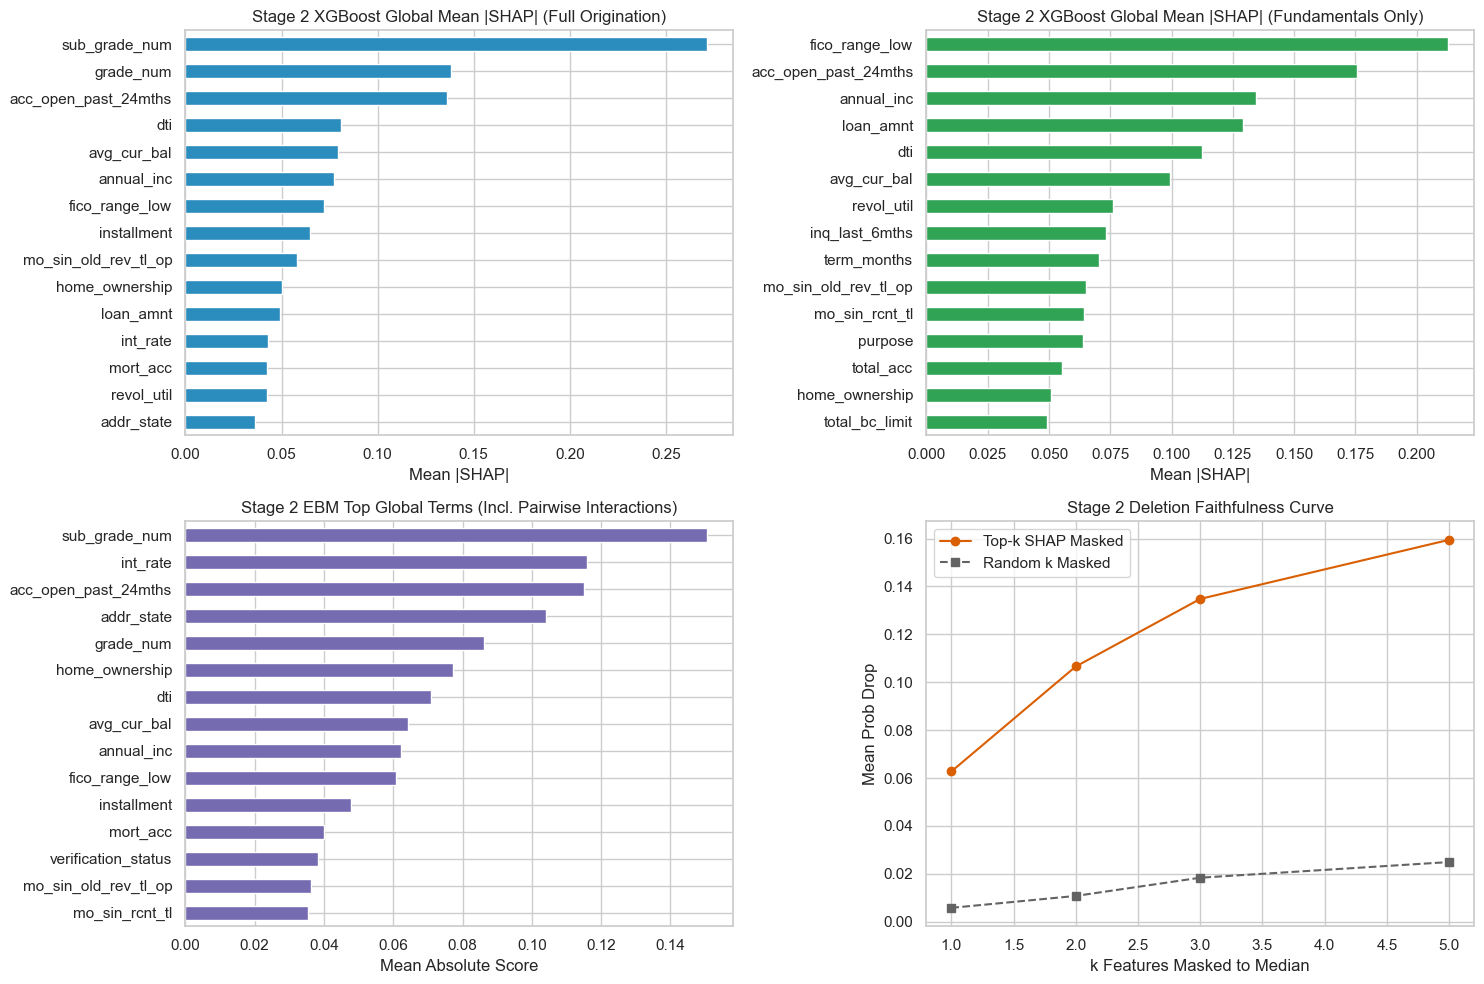

In [ ]:
# Stage 2 XAI: SHAP (cached .npz/.pt) + EBM + shapiq Interactions + Faithfulness/Stability/Sparsity Evaluation
N_EXPLAIN_S2 = 2000
X2_eval_enc = X2_te_enc[:N_EXPLAIN_S2]
X2f_eval_enc = X2f_te_enc[:N_EXPLAIN_S2]
y2_eval = y2_te.iloc[:N_EXPLAIN_S2].to_numpy()
p2_eval = s2_xgb.predict_proba(X2_eval_enc)[:, 1]
p2f_eval = s2_xgb_fund.predict_proba(X2f_eval_enc)[:, 1]

s2_shap, s2_base, _ = load_or_compute_xgb_shap(
    "stage2_xgb_full_shap", s2_xgb, X2_eval_enc, y2_eval, p2_eval, s2_enc_names
)
s2f_shap, s2f_base, _ = load_or_compute_xgb_shap(
    "stage2_xgb_fund_shap", s2_xgb_fund, X2f_eval_enc, y2_eval, p2f_eval, s2f_enc_names
)

# shapiq 2-way interactions on n=60 test rows for Stage 2
sq2 = shapiq.TreeExplainer(model=s2_xgb, max_order=2, index="k-SII")
s2_pair_sums = {}
for i in range(60):
    iv = sq2.explain(X2_eval_enc[i])
    for tup, val in iv.dict_values.items():
        if len(tup) == 2:
            name = f"{s2_enc_names[tup[0]]} x {s2_enc_names[tup[1]]}"
            s2_pair_sums[name] = s2_pair_sums.get(name, 0.0) + abs(float(val))
s2_pairs_df = (
    pd.Series({k: v / 60.0 for k, v in s2_pair_sums.items()})
    .sort_values(ascending=False)
    .to_frame("mean_abs_shapiq_2way")
)
print("Top Stage 2 2-way Shapley interactions (shapiq, n=60):")
display(s2_pairs_df.head(10))

# Evaluate Stage 2 explanations
s2_eval_metrics, s2_del_shap, s2_del_rand = evaluate_explanations(
    s2_xgb, X2_eval_enc, X2_tr_enc, s2_shap, s2_base
)
print("Stage 2 Explanation Evaluation:", s2_eval_metrics)

# Visual summary: Global SHAP (Full vs Fundamentals), EBM Global, and Deletion Curve
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

pd.Series(np.abs(s2_shap).mean(axis=0), index=s2_enc_names).sort_values().tail(15).plot(
    kind="barh", ax=axes[0, 0], color="#2b8cbe"
)
axes[0, 0].set_title("Stage 2 XGBoost Global Mean |SHAP| (Full Origination)")
axes[0, 0].set_xlabel("Mean |SHAP|")

pd.Series(np.abs(s2f_shap).mean(axis=0), index=s2f_enc_names).sort_values().tail(15).plot(
    kind="barh", ax=axes[0, 1], color="#31a354"
)
axes[0, 1].set_title("Stage 2 XGBoost Global Mean |SHAP| (Fundamentals Only)")
axes[0, 1].set_xlabel("Mean |SHAP|")

ebm2_glob = s2_ebm.explain_global().data()
pd.Series(ebm2_glob["scores"], index=ebm2_glob["names"]).sort_values().tail(15).plot(
    kind="barh", ax=axes[1, 0], color="#756bb1"
)
axes[1, 0].set_title("Stage 2 EBM Top Global Terms (Incl. Pairwise Interactions)")
axes[1, 0].set_xlabel("Mean Absolute Score")

ks2 = sorted(s2_del_shap.keys())
axes[1, 1].plot(ks2, [s2_del_shap[k] for k in ks2], marker="o", label="Top-k SHAP Masked", color="#d95f02")
axes[1, 1].plot(ks2, [s2_del_rand[k] for k in ks2], marker="s", linestyle="--", label="Random k Masked", color="#636363")
axes[1, 1].set_title("Stage 2 Deletion Faithfulness Curve")
axes[1, 1].set_xlabel("k Features Masked to Median")
axes[1, 1].set_ylabel("Mean Prob Drop")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Local Stakeholder Explanations: Sample High-Risk Default vs. Low-Risk Paid (Stage 2)
high_i = int(np.argmax(p2_eval * (y2_eval == 1)))
low_i = int(np.argmin(p2_eval + (y2_eval == 1)))

for label, idx in [("High-Risk Actual Default", high_i), ("Low-Risk Actual Fully Paid", low_i)]:
    local_df = pd.DataFrame({
        "feature": s2_enc_names,
        "value": X2_te.iloc[idx][s2_enc_names].values,
        "shap_log_odds": s2_shap[idx],
    })
    local_df["abs_shap"] = local_df["shap_log_odds"].abs()
    top_local = local_df.sort_values("abs_shap", ascending=False).head(8).drop(columns="abs_shap")
    print("=" * 75)
    print(f"{label} | test_idx={idx} | true={y2_eval[idx]} | P(default)={p2_eval[idx]:.3f}")
    display(top_local)

High-Risk Actual Default | test_idx=1289 | true=1 | P(default)=0.442


,feature,value,shap_log_odds
5,sub_grade_num,16.0,0.301896
16,revol_util,97.6,0.226427
4,grade_num,4.0,0.184535
17,bc_util,101.2,0.160809
0,loan_amnt,19200.0,0.157578
30,home_ownership,RENT,0.085394
3,installment,671.33,0.084364
23,acc_open_past_24mths,3.0,-0.076321


Low-Risk Actual Fully Paid | test_idx=1085 | true=0 | P(default)=0.013


,feature,value,shap_log_odds
5,sub_grade_num,2.0,-0.672313
10,fico_range_low,770.0,-0.378266
23,acc_open_past_24mths,1.0,-0.258478
20,avg_cur_bal,44204.0,-0.254548
2,int_rate,6.49,-0.201902
4,grade_num,1.0,-0.193019
7,dti,5.82,-0.192228
6,annual_inc,81600.0,-0.086548


---
## 3. Stakeholder Desiderata & Explanation Evaluation Summary

| Stakeholder | Transparency Question | Chosen Explanations | Quantitative / Empirical Check |
|---|---|---|---|
| **Loan Applicant** | *"Why was I rejected / rated high risk, and what levers matter?"* | Local `SHAP` attribution + `EBM` additive terms (with Stage 1 prior-odds calibration note) | **Sparsity (80% mass):** ~2.3 features (Stage 1) / ~11.2 features (Stage 2) |
| **Risk Analyst / Underwriter** | *"Is the model learning genuine risk factors vs. pricing/artifacts, and how do features interact?"* | Global `SHAP` (Full vs. Fundamentals-Only) + `EBM` shape functions + `shapiq` 2-way interactions | `risk_score x emp_length_years`, `dti x risk_score`, `sub_grade_num x acc_open_past_24mths` |
| **Auditor / Regulator** | *"Are explanations faithful to the model and stable across near-identical applicants?"* | `XGBoost` vs. glass-box `LogReg`/`EBM` comparison + Deletion curves + Noise-jitter stability | **Additivity:** `<= 1.3e-5` error; **Stage 2 Stability $\rho$:** `0.9182`; **Deletion drop:** strongly exceeds random masking |